In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from PIL.ImageColor import colormap
from PIL.ImagePalette import wedge

In [113]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

In [114]:
df = pd.read_csv('../data/processed/respostas_limpas.csv')

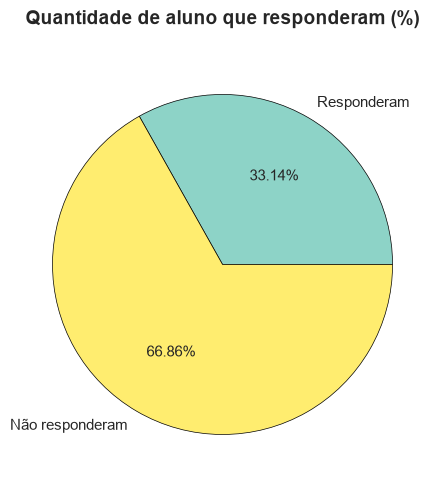

In [115]:
contagem = [len(df), 353 - len(df)]
rotulos = ['Responderam', 'Não responderam']
cores_paleta = plt.cm.Set3(np.linspace(0, 1, len(contagem)))

fig, ax = plt.subplots(figsize=(5,5))

wedges, texts, autotexts = ax.pie(
    contagem,
    labels=rotulos,
    autopct='%1.2f%%',
    startangle=0,
    colors=cores_paleta,
    shadow=False,
    pctdistance=0.6,
    labeldistance=1.1,
    wedgeprops={'edgecolor':'black', 'linewidth':0.5},
)


ax.set_title('Quantidade de aluno que responderam (%)', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

In [116]:
materias_sem_interesse = df[['status_fcal', 'status_linear', 'status_calc1', 'status_calc2']].copy()

materias_sem_interesse.head(5)

respostas_para_remover = [
    'Já cursei e fui aprovado(a)',
    'Já cursei e fui reprovado(a)',
    'Não tenho interesse'
]

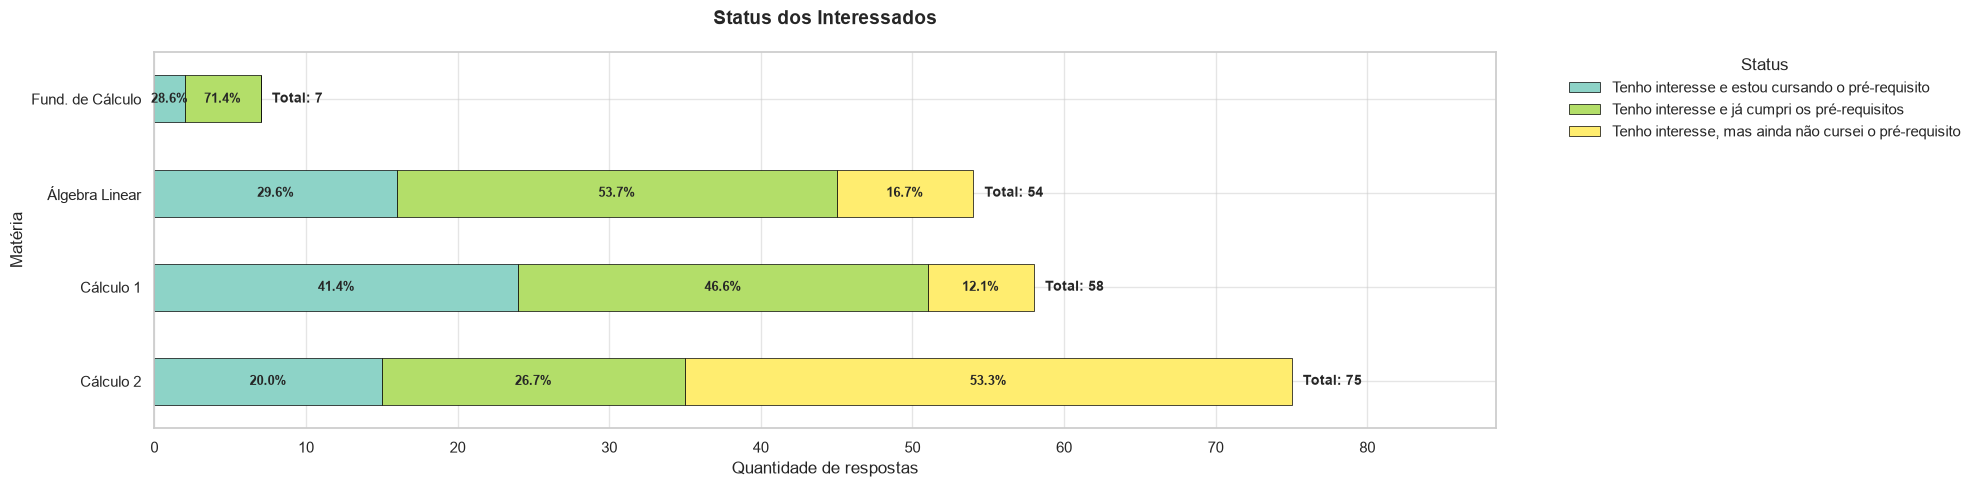

In [117]:
materias = ['status_fcal', 'status_linear', 'status_calc1', 'status_calc2']

contagem = df[materias].apply(pd.Series.value_counts).fillna(0)
contagem = contagem.drop(labels=respostas_para_remover, errors='ignore')

nomes_grafico = {
    'status_fcal': 'Fund. de Cálculo',
    'status_linear': 'Álgebra Linear',
    'status_calc1': 'Cálculo 1',
    'status_calc2': 'Cálculo 2'
}
contagem_plot = contagem.T.rename(index=nomes_grafico)

totais_por_materia = contagem_plot.sum(axis=1)

fig, ax = plt.subplots(figsize=(20, 5))

contagem_plot.plot(
    kind='barh',
    stacked=True,
    colormap='Set3',
    edgecolor='black',
    linewidth=0.5,
    ax=ax,
)

for container in ax.containers:
    labels = []
    for patch in container:
        largura_fatia = patch.get_width()

        y_pos = int(round(patch.get_y() + patch.get_height() / 2))
        total_materia = totais_por_materia.iloc[y_pos]

        if largura_fatia > 0 and total_materia > 0:
            pct = (largura_fatia / total_materia) * 100
            labels.append(f'{pct:.1f}%')
        else:
            labels.append('')

    ax.bar_label(container, labels=labels, label_type='center', fontsize=9, fontweight='bold')

for i, total in enumerate(totais_por_materia):
    ax.text(
        x=total + (totais_por_materia.max() * 0.01),
        y=i,
        s=f'Total: {int(total)}',
        va='center',
        ha='left',
        fontweight='bold',
        fontsize=10
    )

ax.set_title('Status dos Interessados', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Quantidade de respostas', fontsize=12)
ax.set_ylabel('Matéria', fontsize=12)

ax.set_xlim(0, totais_por_materia.max() * 1.18)

ax.legend(title='Status', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., frameon=False)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [118]:
materias_sem_interesse = df[['status_fcal', 'status_linear', 'status_calc1', 'status_calc2']].copy()

materias_sem_interesse.head(5)

respostas_para_remover = [
    'Tenho interesse e já cumpri os pré-requisitos',
    'Tenho interesse e estou cursando o pré-requisito',
    'Tenho interesse, mas ainda não cursei o pré-requisito'
]

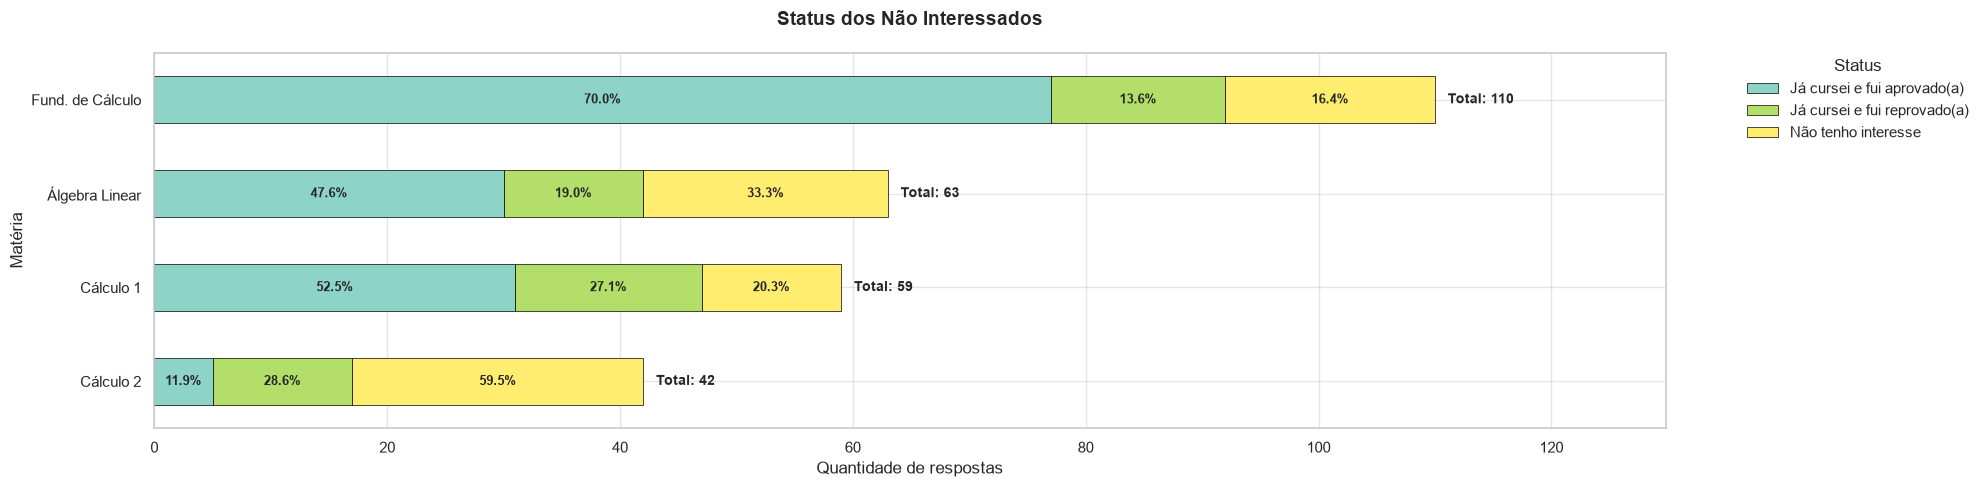

In [119]:
materias = ['status_fcal', 'status_linear', 'status_calc1', 'status_calc2']

contagem = df[materias].apply(pd.Series.value_counts).fillna(0)
contagem = contagem.drop(labels=respostas_para_remover, errors='ignore')

nomes_grafico = {
    'status_fcal': 'Fund. de Cálculo',
    'status_linear': 'Álgebra Linear',
    'status_calc1': 'Cálculo 1',
    'status_calc2': 'Cálculo 2'
}
contagem_plot = contagem.T.rename(index=nomes_grafico)

totais_por_materia = contagem_plot.sum(axis=1)

fig, ax = plt.subplots(figsize=(20, 5))

contagem_plot.plot(
    kind='barh',
    stacked=True,
    colormap='Set3',
    edgecolor='black',
    linewidth=0.5,
    ax=ax,
)

for container in ax.containers:
    labels = []
    for patch in container:
        largura_fatia = patch.get_width()

        y_pos = int(round(patch.get_y() + patch.get_height() / 2))
        total_materia = totais_por_materia.iloc[y_pos]

        if largura_fatia > 0 and total_materia > 0:
            pct = (largura_fatia / total_materia) * 100
            labels.append(f'{pct:.1f}%')
        else:
            labels.append('')

    ax.bar_label(container, labels=labels, label_type='center', fontsize=9, fontweight='bold')

for i, total in enumerate(totais_por_materia):
    ax.text(
        x=total + (totais_por_materia.max() * 0.01),
        y=i,
        s=f'Total: {int(total)}',
        va='center',
        ha='left',
        fontweight='bold',
        fontsize=10
    )

ax.set_title('Status dos Não Interessados', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Quantidade de respostas', fontsize=12)
ax.set_ylabel('Matéria', fontsize=12)

ax.set_xlim(0, totais_por_materia.max() * 1.18)

ax.legend(title='Status', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., frameon=False)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

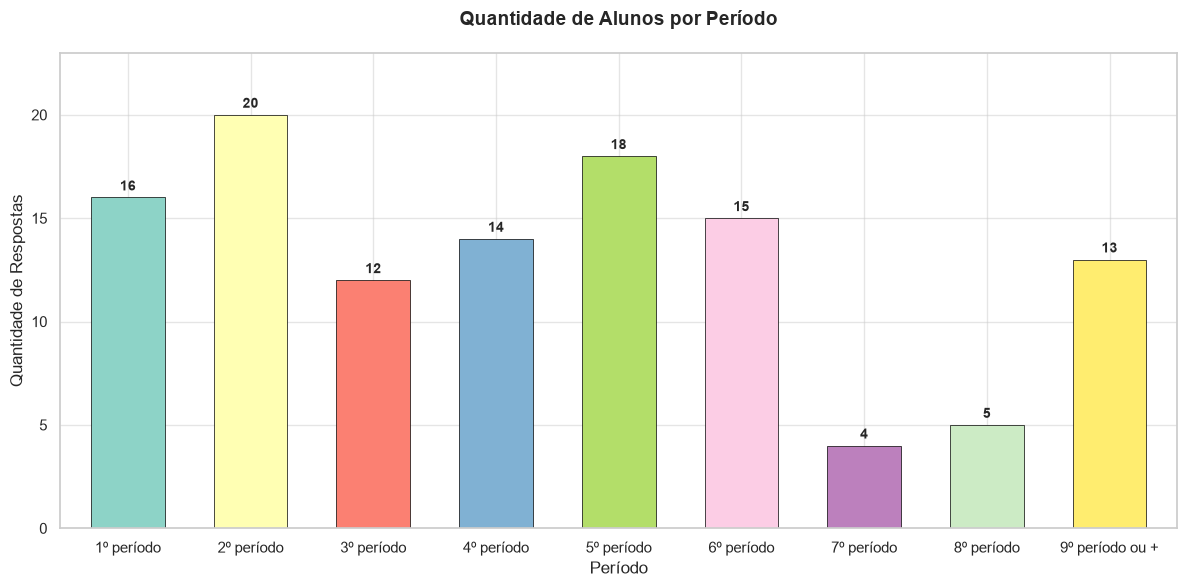

In [136]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Lista com a ordem cronológica exata dos períodos
ordem_periodos = [
    '1º período',
    '2º período',
    '3º período',
    '4º período',
    '5º período',
    '6º período',
    '7º período',
    '8º período',
    '9º período ou +'
]

# 2. Contagem e reordenação
periodo_contagem = df['periodo'].value_counts().reindex(ordem_periodos).fillna(0)

# 3. Configuração da figura
fig, ax = plt.subplots(figsize=(12, 6))

# 'kind=bar' cria colunas verticais
periodo_contagem.plot(
    kind='bar',
    color=plt.cm.Set3(np.linspace(0, 1, len(periodo_contagem))),
    edgecolor='black',
    linewidth=0.5,
    width=0.6,
    ax=ax
)

# 4. Adiciona os valores brutos no TOPO de cada coluna
for patch in ax.patches:
    altura = patch.get_height()
    if altura > 0:
        ax.text(
            x=patch.get_x() + patch.get_width() / 2, # Centro da coluna na horizontal
            y=altura + (periodo_contagem.max() * 0.01), # Um pouco acima da coluna
            s=f'{int(altura)}',
            ha='center',
            va='bottom',
            fontweight='bold',
            fontsize=10
        )

# 5. Personalizações visuais
ax.set_title('Quantidade de Alunos por Período', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Período', fontsize=12)
ax.set_ylabel('Quantidade de Respostas', fontsize=12)

# Rotaciona os rótulos do eixo X para não encavalarem
plt.xticks(rotation=0, ha='center')  # Use rotation=45 se os textos ficarem apertados

# Folga no eixo Y para o número no topo não ser cortado
limite_y = max(periodo_contagem.max() * 1.15, 1)
ax.set_ylim(0, limite_y)

plt.tight_layout()
plt.show()

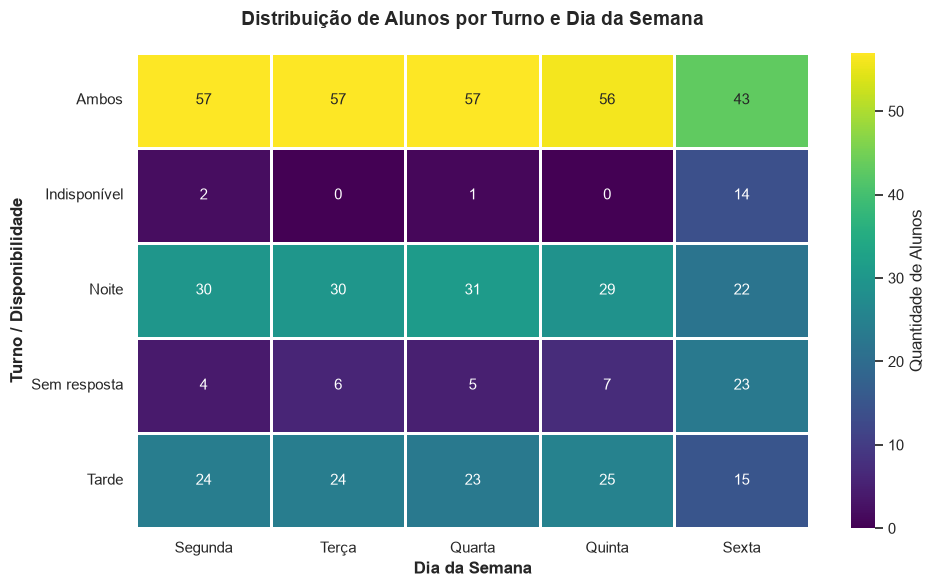

In [143]:
# 1. Lista com as colunas dos dias da semana
cols_dias = ['turno_segunda', 'turno_terca', 'turno_quarta', 'turno_quinta', 'turno_sexta']

# 2. Gera a tabela cruzada de contagem
df_heatmap = df[cols_dias].apply(pd.Series.value_counts).fillna(0)

# Renomeia as colunas para exibição no gráfico
nomes_dias = {
    'turno_segunda': 'Segunda',
    'turno_terca': 'Terça',
    'turno_quarta': 'Quarta',
    'turno_quinta': 'Quinta',
    'turno_sexta': 'Sexta'
}
df_heatmap = df_heatmap.rename(columns=nomes_dias)

# -------------------------------------------------------------------------
# PLOTAGEM DO HEATMAP
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    df_heatmap,
    annot=True,
    fmt='g',
    cmap='viridis',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Quantidade de Alunos'},  # <--- CORRIGIDO AQUI (sem o 'k')
    ax=ax
)

# Ajustes estéticos
ax.set_title('Distribuição de Alunos por Turno e Dia da Semana', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Dia da Semana', fontsize=12, fontweight='bold')
ax.set_ylabel('Turno / Disponibilidade', fontsize=12, fontweight='bold')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

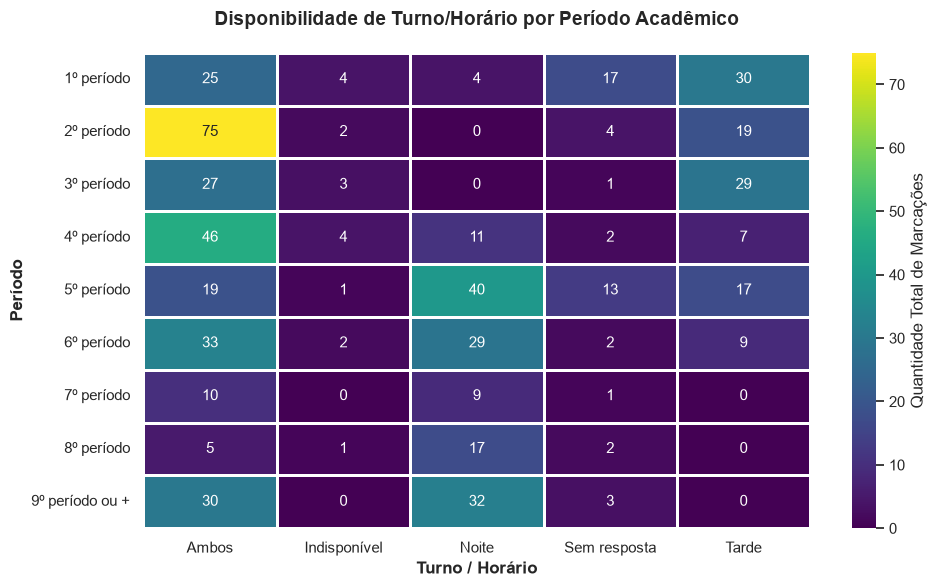

In [150]:
# 1. Colunas dos dias da semana
cols_dias = ['turno_segunda', 'turno_terca', 'turno_quarta', 'turno_quinta', 'turno_sexta']

# 2. Transforma as colunas dos dias em uma única estrutura (Melt)
df_unificado = df.melt(
    id_vars=['periodo'],
    value_vars=cols_dias,
    var_name='dia',
    value_name='turno'
)

# 3. Cria a tabela cruzada entre 'periodo' e 'turno'
tabela_cruzada = pd.crosstab(df_unificado['periodo'], df_unificado['turno'])

# 4. Reordena os períodos em ordem cronológica (1º ao 9º)
ordem_periodos = [
    '1º período',
    '2º período',
    '3º período',
    '4º período',
    '5º período',
    '6º período',
    '7º período',
    '8º período',
    '9º período ou +'
]
tabela_cruzada = tabela_cruzada.reindex(ordem_periodos).fillna(0)

# -------------------------------------------------------------------------
# PLOTAGEM DO HEATMAP
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    tabela_cruzada,
    annot=True,
    fmt='.0f',
    cmap='viridis',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Quantidade Total de Marcações'},
    ax=ax
)

ax.set_title('Disponibilidade de Turno/Horário por Período Acadêmico', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Turno / Horário', fontsize=12, fontweight='bold')
ax.set_ylabel('Período', fontsize=12, fontweight='bold')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

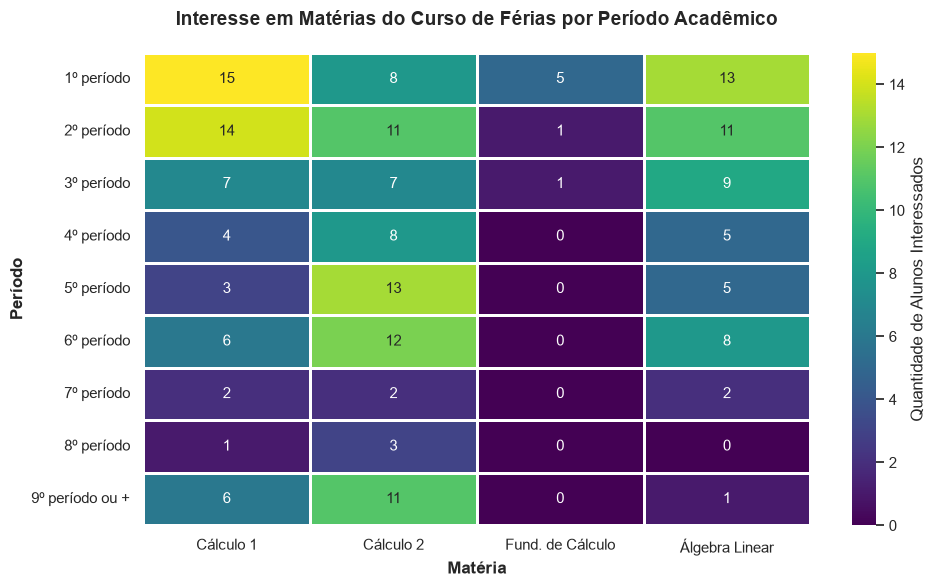

In [152]:
# 1. Lista de colunas das matérias
materias = ['status_fcal', 'status_linear', 'status_calc1', 'status_calc2']

# Dicionário para renomear os códigos das colunas para nomes legíveis
nomes_materias = {
    'status_fcal': 'Fund. de Cálculo',
    'status_linear': 'Álgebra Linear',
    'status_calc1': 'Cálculo 1',
    'status_calc2': 'Cálculo 2'
}

# 2. Unifica as colunas das matérias mantendo a referência do 'periodo'
df_materias_melt = df.melt(
    id_vars=['periodo'],
    value_vars=materias,
    var_name='materia',
    value_name='status'
)

# Substitui os nomes das colunas pelos nomes amigáveis
df_materias_melt['materia'] = df_materias_melt['materia'].map(nomes_materias)

# 3. Filtra APENAS os status que indicam interesse no curso de férias
# (Ajuste a lista abaixo com a frase exata do seu formulário caso necessário, ex: 'Tenho interesse em cursar')
respostas_descartar = [
    'Já cursei e fui aprovado(a)',
    'Já cursei e fui reprovado(a)',
    'Não tenho interesse'
]
df_interesse = df_materias_melt[~df_materias_melt['status'].isin(respostas_descartar)]

# 4. Cria a tabela cruzada (Linhas = Períodos, Colunas = Matérias)
tabela_materia_periodo = pd.crosstab(
    df_interesse['periodo'],
    df_interesse['materia']
)

# 5. Ordena os períodos do 1º ao 9º+
ordem_periodos = [
    '1º período',
    '2º período',
    '3º período',
    '4º período',
    '5º período',
    '6º período',
    '7º período',
    '8º período',
    '9º período ou +'
]
tabela_materia_periodo = tabela_materia_periodo.reindex(ordem_periodos).fillna(0)

# -------------------------------------------------------------------------
# PLOTAGEM DO HEATMAP
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    tabela_materia_periodo,
    annot=True,
    fmt='.0f',
    cmap='viridis',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Quantidade de Alunos Interessados'},
    ax=ax
)

ax.set_title('Interesse em Matérias do Curso de Férias por Período Acadêmico', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Matéria', fontsize=12, fontweight='bold')
ax.set_ylabel('Período', fontsize=12, fontweight='bold')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

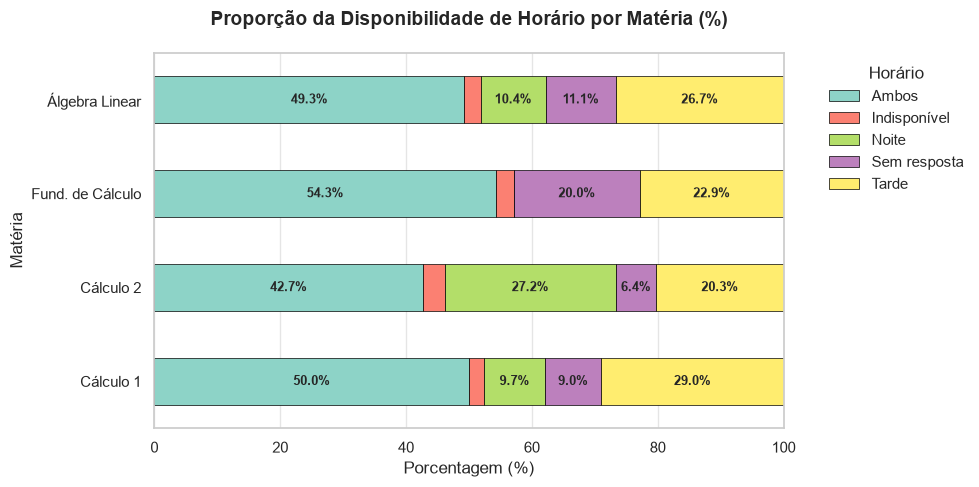

In [157]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Tabela cruzada entre matéria e horário
tabela_materia_horario = pd.crosstab(
    df_cruzado['materia'],
    df_cruzado['horario_disponivel']
)

# 2. Normaliza por linha (calcula a proporção de cada turno por matéria)
tabela_pct = tabela_materia_horario.div(tabela_materia_horario.sum(axis=1), axis=0) * 100

# 3. Plotagem
fig, ax = plt.subplots(figsize=(10, 5))

tabela_pct.plot(
    kind='barh',
    stacked=True,
    colormap='Set3',
    edgecolor='black',
    linewidth=0.5,
    ax=ax
)

# Adiciona os rótulos de porcentagem dentro das fatias
for container in ax.containers:
    labels = []
    for patch in container:
        largura = patch.get_width()
        labels.append(f'{largura:.1f}%' if largura > 5 else '') # Exibe só se for > 5%
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9, fontweight='bold')

ax.set_title('Proporção da Disponibilidade de Horário por Matéria (%)', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Porcentagem (%)', fontsize=12)
ax.set_ylabel('Matéria', fontsize=12)
ax.legend(title='Horário', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

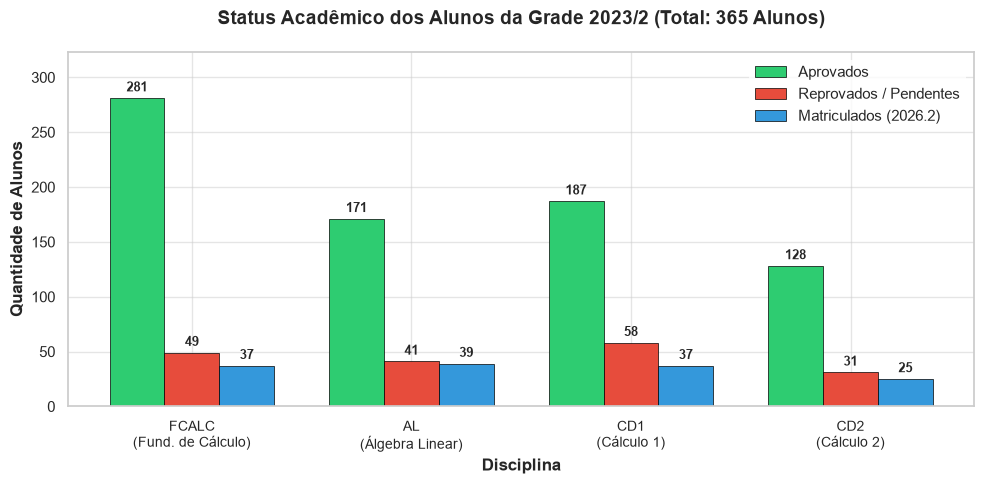

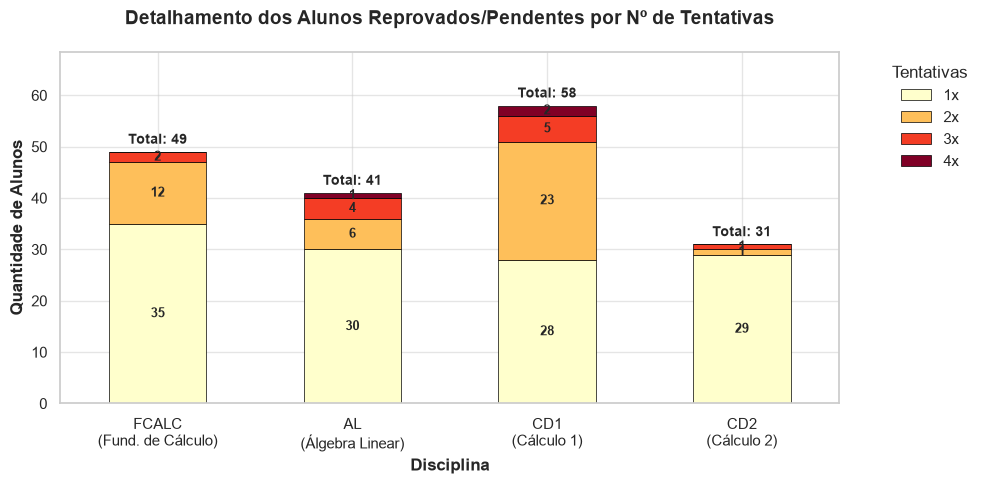

In [158]:
# Configuração do estilo visual
sns.set_theme(style="whitegrid")

# 1. Estruturação dos Dados
disciplinas = ['FCALC', 'AL', 'CD1', 'CD2']
nomes_completos = ['Fund. de Cálculo', 'Álgebra Linear', 'Cálculo 1', 'Cálculo 2']

matriculados = [37, 39, 37, 25]
aprovados = [281, 171, 187, 128]
reprovados_totais = [49, 41, 58, 31]

# Detalhamento de reprovações: [1x, 2x, 3x, 4x]
reprovacoes_detalhado = {
    'FCALC': [35, 12, 2, 0],
    'AL': [30, 6, 4, 1],
    'CD1': [28, 23, 5, 2],
    'CD2': [29, 1, 1, 0]
}

df_reprov = pd.DataFrame(reprovacoes_detalhado, index=['1x', '2x', '3x', '4x']).T

# -------------------------------------------------------------------------
# GRÁFICO 1: Status Geral por Disciplina
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(disciplinas))
width = 0.25

rects1 = ax.bar(x - width, aprovados, width, label='Aprovados', color='#2ecc71', edgecolor='black', linewidth=0.5)
rects2 = ax.bar(x, reprovados_totais, width, label='Reprovados / Pendentes', color='#e74c3c', edgecolor='black', linewidth=0.5)
rects3 = ax.bar(x + width, matriculados, width, label='Matriculados (2026.2)', color='#3498db', edgecolor='black', linewidth=0.5)

ax.set_title('Status Acadêmico dos Alunos da Grade 2023/2 (Total: 365 Alunos)', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Disciplina', fontsize=12, fontweight='bold')
ax.set_ylabel('Quantidade de Alunos', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([f"{d}\n({n})" for d, n in zip(disciplinas, nomes_completos)], fontsize=10)
ax.legend(frameon=True, facecolor='white', edgecolor='none')

# Rótulos de valor acima das barras
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        if height > 0:
            ax.annotate(f'{height}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom', fontweight='bold', fontsize=9)

ax.set_ylim(0, max(aprovados) * 1.15)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# GRÁFICO 2: Detalhamento de Tentativas de Reprovação (Empilhado)
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))

df_reprov.plot(
    kind='bar',
    stacked=True,
    colormap='YlOrRd',
    edgecolor='black',
    linewidth=0.5,
    ax=ax
)

ax.set_title('Detalhamento dos Alunos Reprovados/Pendentes por Nº de Tentativas', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Disciplina', fontsize=12, fontweight='bold')
ax.set_ylabel('Quantidade de Alunos', fontsize=12, fontweight='bold')
plt.xticks(ticks=range(len(disciplinas)), labels=[f"{d}\n({n})" for d, n in zip(disciplinas, nomes_completos)], rotation=0)

# Valores dentro de cada fatia empilhada
for container in ax.containers:
    labels = [f'{int(v)}' if v > 0 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9, fontweight='bold')

# Totais no topo de cada coluna
for i, total in enumerate(df_reprov.sum(axis=1)):
    ax.text(i, total + 1, f'Total: {int(total)}', ha='center', va='bottom', fontweight='bold', fontsize=10)

ax.set_ylim(0, max(df_reprov.sum(axis=1)) * 1.18)
ax.legend(title='Tentativas', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

plt.tight_layout()
plt.show()